## Parte 1

1- Contou-se o número de erros de impressão da primeira página de um jornal durante 50 dias, obtendo-se os resultados abaixo:

| 1 | 2  | 3 | 4  | 5  | 6  | 7  | 8  | 9  | 10 |
|--:|---:|--:|---:|---:|---:|---:|---:|---:|---:|
| 8 | 11 | 8 | 12 | 14 | 13 | 11 | 14 | 14 | 15 |
| 6 | 10 | 14 | 19 | 6 | 12 | 7 | 5 | 8 | 8 |
| 10 | 16 | 10 | 12 | 12 | 8 | 11 | 6 | 7 | 12 |
| 7 | 10 | 14 | 5 | 12 | 7 | 9 | 12 | 11 | 9 |
| 14 | 8 | 14 | 8 | 12 | 10 | 12 | 22 | 7 | 15 |



 - Calcule as frequências relativas e as frequências relativas acumuladas. Considere a representação individual dos erros e em intervalos de 5 valores
 - Calcule a média, desvio-padrão e assimetria;  
 - Qual a frequência de valores maiores que 10? Qual a frequência de valores menores que 15? Qual a frequência de valores maiores que 10 e menores que 15? 

Aqui as variáveis podem ser tratadas como discretas, porque o número de erros é sempre um inteiro. Portanto, não será feita a tabela de classes.

In [1]:
import pandas as pd
import numpy as np

dados = [
    8, 11, 8, 12, 14, 13, 11, 14, 14, 15,
    6, 10, 14, 19, 6, 12, 7, 5, 8, 8, 10,
    16, 10, 12, 12, 8, 11, 6, 7, 12, 7, 10,
    14, 5, 12, 7, 9, 12, 11, 9, 14, 8, 14,
    8, 12, 10, 12, 22, 7, 15
]   

n = len(dados)

serie = pd.Series(dados)

serie_ord = serie.sort_values()

tabela = (
    serie.value_counts()
    .sort_index()
    .rename_axis("xi")
    .reset_index(name="fi")
)

tabela["fri"] = tabela["fi"] / tabela["fi"].sum()
tabela["Fac"] = tabela["fi"].cumsum()
tabela["Fra"] = tabela["fri"].cumsum()

tabela

,xi,fi,fri,Fac,Fra
0,5,2,0.04,2,0.04
1,6,3,0.06,5,0.10
2,7,5,0.10,10,0.20
3,8,7,0.14,17,0.34
4,9,2,0.04,19,0.38
5,10,5,0.10,24,0.48
6,11,4,0.08,28,0.56
7,12,9,0.18,37,0.74
8,13,1,0.02,38,0.76
9,14,7,0.14,45,0.90


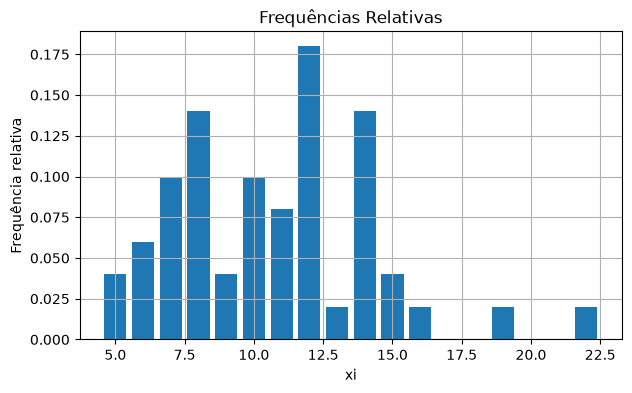

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(tabela['xi'], tabela['fri'])

ax.set_title("Frequências Relativas")
ax.set_xlabel("xi")
ax.set_ylabel("Frequência relativa")
ax.grid(True)

plt.show()

Aqui aqui foi atendida a primeira parte do primeiro item. Na segunda parte, devemos separar os dados em intervalos de cinco valores.

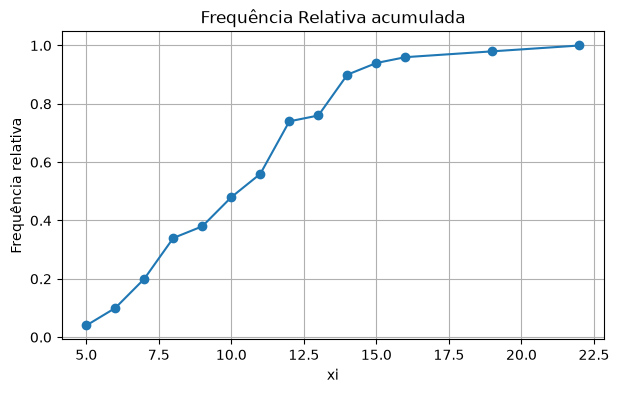

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(tabela['xi'], tabela['Fra'], marker="o")

ax.set_title("Frequência Relativa acumulada")
ax.set_xlabel("xi")
ax.set_ylabel("Frequência relativa")
ax.grid(True)

plt.show()

### Estatísticas.

a média é:

$$ \bar{x} = \sum(fr_i \cdot x_i) $$

a variância populacional é:

$$
\sigma^2 =
\frac{\sum f_i (x_i - \bar{x})^2}{n}
$$

e o desvio padrão:

$$
\sigma = \sqrt{\sigma^2}
$$

e a assimetria pelo terceiro momento padronizado:

$$
    g =
    \frac{\sum f_i (x_i - \bar{x})^3}
    {n\,\sigma^3}
$$


### Cálculo da Média.

In [4]:
media_erros = (tabela['fri'] * tabela['xi']).sum()

var_erros = (
    tabela['fi'] * (tabela['xi'] - media_erros)**2
).sum() / n

std_erros = var_erros**0.5

g_erros = (
    tabela['fi'] * (tabela['xi'] - media_erros)**3
).sum() / (n * std_erros**3)

cv_erros = std_erros/media_erros

print(f'A media dos erros é: {media_erros:.2f}')
print(f'A variância dos erros é: {var_erros:.2f}')
print(f'O desvio padrão dos erros é: {std_erros:.2f}')  
print(f'A excentricidade dos erros é: {g_erros:.2f}')
print(f'O coeficiente de variação dos erros é: {cv_erros:.2f}')

A media dos erros é: 10.74
A variância dos erros é: 12.35
O desvio padrão dos erros é: 3.51
A excentricidade dos erros é: 0.67
O coeficiente de variação dos erros é: 0.33


In [5]:
classes = [
    "5 a 9",
    "10 a 14",
    "15 a 19",
    "20 a 24"
]

# Somar as frequências fi de cada classe
soma_f1 = tabela["fi"].iloc[0:5].sum()
soma_f2 = tabela["fi"].iloc[5:10].sum()
soma_f3 = tabela["fi"].iloc[10:13].sum()
soma_f4 = tabela["fi"].iloc[13:14].sum()

frequencias_classes = [
    soma_f1,
    soma_f2,
    soma_f3,
    soma_f4
]

tabela_classes = pd.DataFrame({
    "classe": classes,
    "fi": frequencias_classes
})

n = tabela_classes["fi"].sum()

tabela_classes['fri'] = tabela_classes['fi']/tabela_classes['fi'].sum()

tabela_classes['Fra'] = tabela_classes['fri'].cumsum()



tabela_classes


,classe,fi,fri,Fra
0,5 a 9,19,0.38,0.38
1,10 a 14,26,0.52,0.90
2,15 a 19,4,0.08,0.98
3,20 a 24,1,0.02,1.00


In [6]:
for i in range(0, len(serie_ord), 10):
    print(serie_ord.iloc[i:i+10].to_list())

[5, 5, 6, 6, 6, 7, 7, 7, 7, 7]
[8, 8, 8, 8, 8, 8, 8, 9, 9, 10]
[10, 10, 10, 10, 11, 11, 11, 11, 12, 12]
[12, 12, 12, 12, 12, 12, 12, 13, 14, 14]
[14, 14, 14, 14, 14, 15, 15, 16, 19, 22]


In [7]:
contador_1 = 0

for i in serie_ord:
    if i > 10:
        contador_1 += 1

print(f'O número de erros maiores que 10 é: {contador_1}.')

contador_2 = 0

for i in serie_ord:
    if i < 15:
        contador_2 += 1

print(f'O número de erros menores que 15 é: {contador_2}.')

contador_3 = 0

for i in serie_ord:
    if i < 15 and i > 10:
        contador_3 += 1

print(f'O número de erros menores que 15 e maiores que 10 é: {contador_3}.')


O número de erros maiores que 10 é: 26.
O número de erros menores que 15 é: 45.
O número de erros menores que 15 e maiores que 10 é: 21.


Os valores maiores que 10 têm uma frequência igual a 26  
Os valores menores que 15 têm uma frequência igual a 45  
Os valores menores que 15  e maiores que 10 têm uma frequência igual a 21  


### Mediana, Moda Q1 e Q3

In [8]:
md_erros = (serie_ord.iloc[24]+ serie_ord.iloc[25])/2
q1_erros = (serie_ord.iloc[11]+ serie_ord.iloc[12])/2
q3_erros = (serie_ord.iloc[36]+ serie_ord.iloc[37])/2

print(f'A mediana é : {md_erros}')
print(f'O Q1 é : {q1_erros}')
print(f'O Q3 é : {q3_erros}')

A mediana é : 11.0
O Q1 é : 8.0
O Q3 é : 12.5


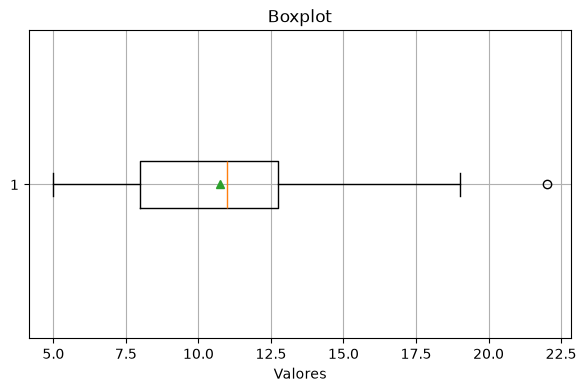

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(serie_ord, orientation='horizontal', showmeans=True)

ax.set_title("Boxplot")
ax.set_xlabel("Valores")
ax.grid(True)

plt.show()

2- Quinze barras de concreto fabricadas nas mesmas condições foram submetidas à testes de flexão. Os valores de carga associados à primeira rachadura e ao colapso estão apresentados a seguir: 

## Cargas

| Nº da barra | Carga da 1ª rachadura | Carga de colapso |
|------------:|----------------------:|------------------:|
| 1  | 10350 | 10350 |
| 2  | 8450  | 9300  |
| 3  | 7200  | 9600  |
| 4  | 5100  | 10300 |
| 5  | 6500  | 9400  |
| 6  | 10600 | 10600 |
| 7  | 6000  | 10100 |
| 8  | 6000  | 9900  |
| 9  | 9500  | 9500  |
| 10 | 6500  | 10200 |
| 11 | 9300  | 9300  |
| 12 | 6000  | 9550  |
| 13 | 6000  | 9550  |
| 14 | 5800  | 10500 |
| 15 | 6500  | 10200 |

- Calcule as frequências relativas e as frequências relativas acumuladas de cada tipo de carga. Considere a representação das cargas em intervalos (1000);  
- Calcule a média, desvio-padrão e assimetria para cada tipo de carga;  
- Calcule o coeficiente de correlação.  

In [10]:

numero_barra = list(range(1, 16))

cargas = [
    10350, 8450, 7200, 5100, 6500,
    10600, 6000, 6000, 9500, 6500,
    9300, 6000, 6000, 5800, 6500
]

tabela_2 = pd.DataFrame({
    "Número da Barra (i)": numero_barra,
    "Carga primeira rachadura (xi)": cargas
})

tabela_2 = (tabela_2
    .sort_values(by="Carga primeira rachadura (xi)")
    .reset_index(drop=True)
)

tabela_2



,Número da Barra (i),Carga primeira rachadura (xi)
0,4,5100
1,14,5800
2,7,6000
3,8,6000
4,12,6000
5,13,6000
6,10,6500
7,5,6500
8,15,6500
9,3,7200


Dividindo em classes de 1000 na carga teremos:

| Nº da classe | frequência |
|------------:|------------:|
| 1  | 5100 a 6100  | 6 |
| 2  | 6100 a 7100  | 3 |
| 3  | 7100 a 8100  | 1 |
| 4  | 8100 a 9100  | 1 |
| 5  | 9100 a 10100 | 2 |
| 6  | 10100 a 11100| 2 |



O exercício fixa como amplitude de classe o valor 1000.

In [11]:
classes_carga = [
                "5100 a 6100",
                "6100 a 7100",
                "7100 a 8100",
                "8100 a 9100",
                "9100 a 10100",
                "10100 a 11100"
                ]

carga = tabela_2["Carga primeira rachadura (xi)"]

soma_f1 = carga[
    (carga >= 5100) & (carga < 6100)
].count()

soma_f2 = carga[
    (carga >= 6100) & (carga < 7100)
].count()

soma_f3 = carga[
    (carga >= 7100) & (carga < 8100)
].count()

soma_f4 = carga[
    (carga >= 8100) & (carga < 9100)
].count()

soma_f5 = carga[
    (carga >= 9100) & (carga < 10100)
].count()

soma_f6 = carga[
    (carga >= 10100) & (carga <= 11100)
].count()

frequencias_classes = [
    soma_f1,
    soma_f2,
    soma_f3,
    soma_f4,
    soma_f5,
    soma_f6
]

dados_carga = pd.DataFrame({
    "Classes de Carga": classes_carga,
    "fi": frequencias_classes
})

n = dados_carga["fi"].sum()

dados_carga['fri'] = dados_carga['fi'] / n

dados_carga['Fra'] = dados_carga['fri'].cumsum()

centro_classe = {'Centro da Classe': [(5100+6100)/2, (6100+7100)/2, (7100+8100)/2, (8100+9100)/2, (9100+10100)/2, (10100+11100)/2]}

dados_carga['Centro da Classe'] = centro_classe['Centro da Classe']


media = (
    dados_carga['fri'] *
    dados_carga['Centro da Classe']
).sum()

var = (
    dados_carga['fi'] *
    (dados_carga['Centro da Classe'] - media)**2
).sum()/n

std = var**0.5
cv = std / media

g_carga = (
    dados_carga['fi'] * (dados_carga['Centro da Classe'] - media)**3
).sum() / (n * std**3)


print(f'Média agrupada: {media:.2f}')
print(f'Variância agrupada: {var:.2f}')
print(f'Desvio padrão agrupado: {std:.2f}')
print(f'O Coeficiente de Variação é: {cv:.2f}')
print(f'A excentricidade é: {g_carga:.2f}')

Média agrupada: 7333.33
Variância agrupada: 3528888.89
Desvio padrão agrupado: 1878.53
O Coeficiente de Variação é: 0.26
A excentricidade é: 0.63


In [12]:
dados_carga

,Classes de Carga,fi,fri,Fra,Centro da Classe
0,5100 a 6100,6,0.400000,0.400000,5600.0
1,6100 a 7100,3,0.200000,0.600000,6600.0
2,7100 a 8100,1,0.066667,0.666667,7600.0
3,8100 a 9100,1,0.066667,0.733333,8600.0
4,9100 a 10100,2,0.133333,0.866667,9600.0
5,10100 a 11100,2,0.133333,1.000000,10600.0


### Os gráficos:

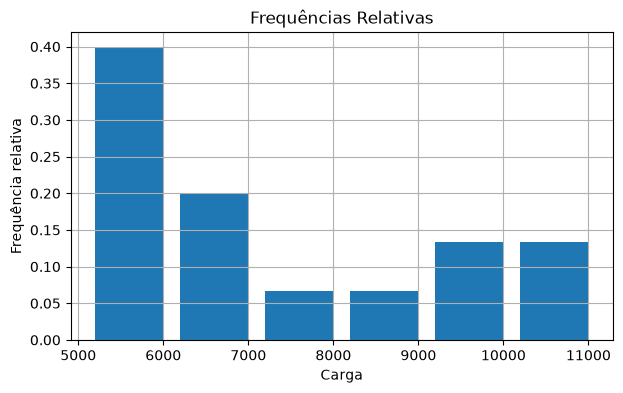

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    dados_carga['Centro da Classe'],
    dados_carga['fri'],
    width=800
)

ax.set_title("Frequências Relativas")
ax.set_xlabel("Carga")
ax.set_ylabel("Frequência relativa")
ax.grid(True)

plt.show()

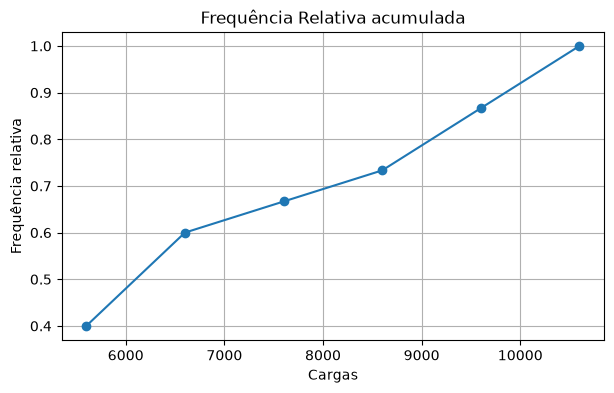

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(dados_carga['Centro da Classe'], dados_carga['Fra'], marker="o")

ax.set_title("Frequência Relativa acumulada")
ax.set_xlabel("Cargas")
ax.set_ylabel("Frequência relativa")
ax.grid(True)

plt.show()

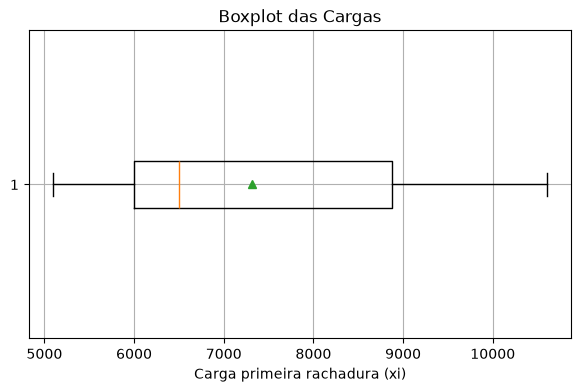

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    tabela_2['Carga primeira rachadura (xi)'],
    orientation='horizontal',
    showmeans=True
)

ax.set_title("Boxplot das Cargas")
ax.set_xlabel("Carga primeira rachadura (xi)")
ax.grid(True)

plt.show()

## As cargas de colapso são:

| Nº da barra| Carga de colapso |
|-----------:|------------------:|
| 1  | 10350 |
| 2  | 9300  |
| 3  | 9600  |
| 4  | 10300 |
| 5  | 9400  |
| 6  | 10600 |
| 7  | 10100 |
| 8  | 9900  |
| 9  | 9500  |
| 10 | 10200 |
| 11 | 9300  |
| 12 | 9550  |
| 13 | 9550  |
| 14 | 10500 |
| 15 | 10200 |



In [16]:
cargas_colapso = sorted([10350, 9300, 9600, 10300, 9400,
                  10600, 10100, 9900, 9500, 10200,
                  9300, 9550, 9550, 10500, 10200])

tabela_3 = pd.DataFrame({
    "Número da Barra (i)": numero_barra,
    "Carga de Colapso (xi)": cargas_colapso
})

tabela_3 = (
    tabela_3
    .sort_values(by="Carga de Colapso (xi)")
    .reset_index(drop=True)
)

tabela_3

,Número da Barra (i),Carga de Colapso (xi)
0,1,9300
1,2,9300
2,3,9400
3,4,9500
4,5,9550
5,6,9550
6,7,9600
7,8,9900
8,9,10100
9,10,10200


Sendo o número de observações o mesmo do item anterior, usaremos 5 classes.  
então as classes seriam dadas por:

In [17]:
# max_colapso = tabela_3['Carga de Colapso (xi)'].max()
# min_colapso = tabela_3['Carga de Colapso (xi)'].min()
# amplitude_colapso = max_colapso - min_colapso
# print(f'A amplitude_colapso é: {amplitude_colapso:.2f}')

O problema define o valor 1000 para a amplitude de classe.

In [18]:
classes_carga_colapso = [
    "9300 a 9400",
    "9400 a 9500",
    "9500 a 9600",
    "9600 a 9700",
    "9700 a 10700"
]

carga_colapso = tabela_3["Carga de Colapso (xi)"]

soma_f1 = carga_colapso[
    (carga_colapso >= 9300) & (carga_colapso < 9560)
].count()

soma_f2 = carga_colapso[
    (carga_colapso >= 9560) & (carga_colapso < 9820)
].count()

soma_f3 = carga_colapso[
    (carga_colapso >= 9820) & (carga_colapso < 10080)
].count()

soma_f4 = carga_colapso[
    (carga_colapso >= 10080) & (carga_colapso < 10340)
].count()

soma_f5 = carga_colapso[
    (carga_colapso >= 10340) & (carga_colapso <= 10600)
].count()

frequencias_classes = [
    soma_f1,
    soma_f2,
    soma_f3,
    soma_f4,
    soma_f5
]

dados_carga_colapso = pd.DataFrame({
    "Classes de Carga": classes_carga_colapso,
    "fi": frequencias_classes
})

n = dados_carga_colapso["fi"].sum()

centro_classe_colapso = [
    (9300 + 9400) / 2,
    (9560 + 9820) / 2,
    (9820 + 10080) / 2,
    (10080 + 10340) / 2,
    (10340 + 10600) / 2
]

dados_carga_colapso["fri"] = dados_carga_colapso["fi"] / n
dados_carga_colapso["Fra"] = dados_carga_colapso["fri"].cumsum()
dados_carga_colapso["Centro da Classe"] = centro_classe_colapso

dados_carga_colapso


,Classes de Carga,fi,fri,Fra,Centro da Classe
0,9300 a 9400,6,0.400000,0.400000,9350.0
1,9400 a 9500,1,0.066667,0.466667,9690.0
2,9500 a 9600,1,0.066667,0.533333,9950.0
3,9600 a 9700,4,0.266667,0.800000,10210.0
4,9700 a 10700,3,0.200000,1.000000,10470.0


### Calcular a média, VAR e std.

In [19]:
media_colapso = (dados_carga_colapso['fri'] * dados_carga_colapso['Centro da Classe']).sum()
var_colapso = (((dados_carga_colapso['Centro da Classe']-media_colapso)**2) * dados_carga_colapso['fri']).sum()
std_colapso = np.sqrt(var_colapso)
cv_colapso = std_colapso/media_colapso

print(f'O valor da média é: {media_colapso:.2f}')
print(f'O valor da variância é: {var_colapso:.2f}')
print(f'O valor do desvio padrão é: {std_colapso:.2f}')
print(f'O valor do coeficiente de variação é: {cv_colapso:.2f}')


O valor da média é: 9866.00
O valor da variância é: 213557.33
O valor do desvio padrão é: 462.12
O valor do coeficiente de variação é: 0.05


### Quantis

O valor da Md é: 9900.00
O valor de Q1 é: 9525.00
O valor de Q3 é: 10250.00


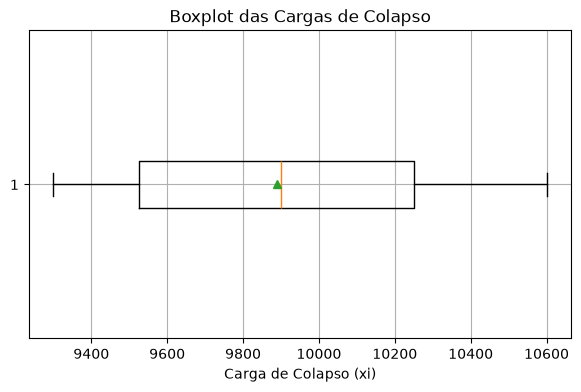

In [20]:
colapso_ord = tabela_3['Carga de Colapso (xi)']
med = colapso_ord[7]
q1_colapso = (colapso_ord[3] + colapso_ord[4]) / 2
q3_colapso = (colapso_ord[10] + colapso_ord[11]) / 2

mediana_colapso = np.median(tabela_3['Carga de Colapso (xi)'])
qq1_colapso = np.quantile(tabela_3['Carga de Colapso (xi)'], 0.25)
qq3_colapso = np.quantile(tabela_3['Carga de Colapso (xi)'], 0.75)

print(f'O valor da Md é: {mediana_colapso:.2f}')
print(f'O valor de Q1 é: {q1_colapso:.2f}')
print(f'O valor de Q3 é: {q3_colapso:.2f}')

fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    tabela_3['Carga de Colapso (xi)'],
    orientation='horizontal',
    showmeans=True
)

ax.set_title("Boxplot das Cargas de Colapso")
ax.set_xlabel("Carga de Colapso (xi)")
ax.grid(True)

plt.show()


3– Sejam os dados de tempos de reação a um estímulo (Y) e acuidade visual (Z) de 20 indivíduos.  

| Indivíduo |  Y  |  Z  |
|----------:|----:|----:|
| 1  | 96  | 90  |
| 2  | 92  | 100 |
| 3  | 106 | 80  |
| 4  | 100 | 90  |
| 5  | 98  | 100 |
| 6  | 104 | 90  |
| 7  | 110 | 80  |
| 8  | 101 | 90  |
| 9  | 116 | 70  |
| 10 | 106 | 90  |
| 11 | 109 | 90  |
| 12 | 100 | 80  |
| 13 | 112 | 90  |
| 14 | 105 | 80  |
| 15 | 118 | 70  |
| 16 | 108 | 90  |
| 17 | 113 | 90  |
| 18 | 112 | 90  |
| 19 | 127 | 60  |
| 20 | 117 | 80  |


- Calcule a distribuição de frequências das duas variáveis aleatórias (considere a representação individual ou por classe).
- Calcule a distribuição de frequências conjunta das duas variáveis aleatórias (considere a representação individual).  
- Calcule o coeficiente de variação de cada uma das duas variáveis aleatórias e interprete-os.  
- Qual a frequência de tempo de reação a um estímulo maior que 100? Qual a frequência de tempo de reação a um estímulo menor que 120? Qual a frequência de tempo de reação a um estímulo maior que 100 e menor que 120?  
- Calcule os quartis das duas distribuições de frequências. Monte o diagrama de Box-Plot.  
- Calcule o coeficiente de correlação entre os tempos de reação a um estímulo e a acuidade visual desse conjunto de indivíduos. Interprete-o. 

### Para a variável y

In [21]:
# distribuição de frequências
import matplotlib.pyplot as plt
n = 20
individuo = list(range(1, 21))

y = [96, 92, 106, 100, 98, 104, 110, 101, 116, 106, 109, 100, 112, 105, 118, 108, 113, 112, 127, 117]
z = [90, 100, 80, 90, 100, 90, 80, 90, 70, 100, 90, 80, 90, 80, 70, 90, 90, 90, 60, 80]
df = pd.DataFrame({
    "indivíduo": individuo,
    "y": y,
    "z": z
})
freq_y = (
    df["y"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_y.columns = ["Y", "fi_y"]
freq_y['Fi_y'] = freq_y['fi_y'].cumsum()
freq_y['fr_y'] = freq_y["fi_y"] / n
freq_y['Frac'] = freq_y["fr_y"].cumsum()
freq_y

,Y,fi_y,Fi_y,fr_y,Frac
0,92,1,1,0.05,0.05
1,96,1,2,0.05,0.10
2,98,1,3,0.05,0.15
3,100,2,5,0.10,0.25
4,101,1,6,0.05,0.30
5,104,1,7,0.05,0.35
6,105,1,8,0.05,0.40
7,106,2,10,0.10,0.50
8,108,1,11,0.05,0.55
9,109,1,12,0.05,0.60


In [22]:
# Valor da média
media_y = (freq_y['Y'] * freq_y['fr_y']).sum()
print(f'A media da variável Y é: {media_y:.2f}')

var_y = (freq_y['fi_y']*((freq_y['Y']-media_y)**2)/n).sum()
print(f'A variância de Y é: {var_y:.2f}')

std_y = np.sqrt(var_y)
print(f'O desvio padrão de Y é: {std_y:.2f}')

cv_y = std_y / media_y
print(f'o Coeficiente de Y é: {cv_y:.2f}')

g = (np.sum(((freq_y['Y']-media_y)**3)*freq_y['fi_y']))/(n*std_y**3)
print(f'A excentricidade é igual a: {g:.2e}')
if g == 0:
    print("Portanto, a curva é simétrica")
elif g>0:
    print('Portanto, curva tem uma cauda para direita')
else:
    print('Portanto. a curva tem uma cauda para a esquerda')

A media da variável Y é: 107.50
A variância de Y é: 68.65
O desvio padrão de Y é: 8.29
o Coeficiente de Y é: 0.08
A excentricidade é igual a: 2.75e-01
Portanto, curva tem uma cauda para direita


Se ainda na variável Y, eu tivesse divido em  5 classes:

Usando a regra de Sturges: $$k = 1+ 3,32\log(20)$$

temos $\approx 6$ 

In [23]:
import pandas as pd

df_y = pd.DataFrame({"Y": sorted(y)})

n = len(y)
limites = [92, 99, 106, 113, 120, 127]

classes_y = [
    f"{limites[i]} a {limites[i + 1]}"
    for i in range(len(limites) - 1)
]

centro_k = [
    (limites[i] + limites[i + 1]) / 2
    for i in range(len(limites) - 1)
]

fi = [
    sum(
        1 for valor in y
        if limites[i] <= valor < limites[i + 1]
    )
    for i in range(len(limites) - 1)
]

# Inclui o limite superior da última classe
fi[-1] = fi[-1] + y.count(limites[-1])

fr = [frequencia / n for frequencia in fi]

Fr = pd.Series(fr).cumsum()

tabela_y = pd.DataFrame({
    "Classes": classes_y,
    "X": centro_k,
    "fi": fi,
    "fr": fr,
    "Fr": Fr
})

tabela_y

,Classes,X,fi,fr,Fr
0,92 a 99,95.5,3,0.15,0.15
1,99 a 106,102.5,5,0.25,0.40
2,106 a 113,109.5,7,0.35,0.75
3,113 a 120,116.5,4,0.20,0.95
4,120 a 127,123.5,1,0.05,1.00


Assim temos o primeiro item respondido.

A média usando os dados classificados por classe é:

In [24]:
med_y = sum((tabela_y['fr']*tabela_y['X']))
print(f'A média é: {med_y}')

A média é: 107.75


A variância usando os dados agrupados por classes é:

$$s^2=\frac{\sum_{i=1}^n \Big(fi\cdot(x - \bar{x})^2\Big)}{n}$$

Enquanto para dados não agrupados é:  

$$s^2=\frac{\sum_{i=1}^n (x - \bar{x})^2}{n}

### Para a variável z

In [25]:
freq_z = (
    df["z"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_z.columns = ["Z", "fi_z"]

# freq_z['Fi_z'] = freq_z['fi_z'].cumsum()
# freq_z['fr_z'] = freq_z['fi_z'] / n
# freq_z['Frac_z'] = freq_z['fr_z'].cumsum()

freq_z

,Z,fi_z
0,60,1
1,70,2
2,80,5
3,90,9
4,100,3


In [26]:
# # Valor da média
# media_z = (freq_z['Z'] * freq_z['fr_z']).sum()
# print(f'A media da variável Z é: {media_z:.2f}')

# var_z = ((freq_z['fi_z']*(freq_z['Z']-media_z)**2)/n).sum()
# print(f'A variância de Z é: {var_z:.2f}')

# std_z = np.sqrt(var_z)
# print(f'O desvio padrão de Z é: {std_z:.2f}')

# cv_z = std_z / media_z
# print(f'o Coeficiente de Z é: {cv_z:.2f}')

Agrupando por classes

In [27]:
from itertools import accumulate
k_z = 1 + 3.2*np.log10(n)

amp_z = max(z) - min(z)
h_z = amp_z/5

classes_z = ['60 a 68', '68 a 76', '76 a 84', '84 a 92', '92 a 100']
centro_z = [64, 72, 80, 88,96]
fi_z = [1, 2, 5, 9, 3]
fr_z = [z / n for z in fi_z]

frac_z = list(accumulate(fr_z))

print(f'O número de classes é {k_z:.0f}')
tabela_z = pd.DataFrame({'Classes':classes_z,
                         'Z':centro_z,
                         'fi':fi_z,
                         'fr':fr_z,
                         'frac':frac_z}
                                                  )
tabela_z


O número de classes é 5


,Classes,Z,fi,fr,frac
0,60 a 68,64,1,0.05,0.05
1,68 a 76,72,2,0.10,0.15
2,76 a 84,80,5,0.25,0.40
3,84 a 92,88,9,0.45,0.85
4,92 a 100,96,3,0.15,1.00


Assim podemos calcular a média dos dados agrupados por classes.

In [28]:
media_z = sum(tabela_z['Z']*tabela_z['fr'])
print(f'A média de Z é {media_z}')

A média de Z é 84.4


Agora é a variância:

In [29]:
var_z = (sum(tabela_z['fi']*(tabela_z['Z']-media_z)**2))/n
s_z = np.sqrt(var_z)
cv_z = s_z / media_z
g_z = sum(((tabela_z['Z']-media_z)**3)*tabela_z['fi'])/(n*s_z**3)
C_z = sum(((tabela_z['Z']-media_z)**4)*tabela_z['fi'])/(n*s_z**4)


print(f'A variância de Z é: {var_z:.2f}')
print(f'O desvio padrão de Z é: {s_z:.2f}')
print(f'O coeficiente de variação de Z é: {cv_z:.2f}')
print(f'A excentricidade de Z é {g_z:.3f}')
print(f'A curtose de Z é {C_z-3:.3f}')


A variância de Z é: 67.04
O desvio padrão de Z é: 8.19
O coeficiente de variação de Z é: 0.10
A excentricidade de Z é -0.695
A curtose de Z é 0.095


## Quantis de Y e Z

In [30]:
y_ord = np.array(sorted(y))
md = (y_ord[9]+y_ord[10])/2
print(y_ord)
print(f'A mediana é: {md:.2f}')
q1 = y_ord[4]
print(f'o valor de Q1 é: {q1:.2f}')
q3 = (y_ord[14])
print(f'o valor de Q3 é: {q3:.2f}')

[ 92  96  98 100 100 101 104 105 106 106 108 109 110 112 112 113 116 117
 118 127]
A mediana é: 107.00
o valor de Q1 é: 100.00
o valor de Q3 é: 112.00


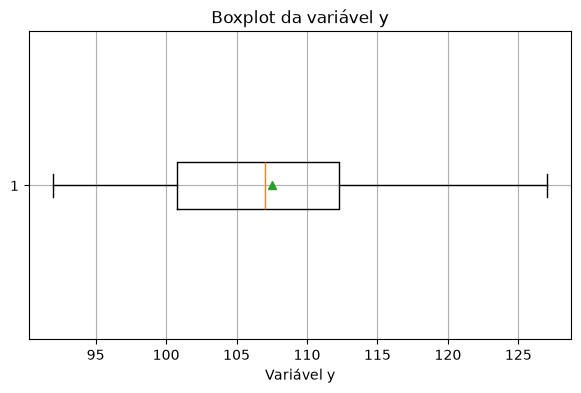

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    y_ord,
    orientation='horizontal',
    showmeans=True
)

ax.set_title("Boxplot da variável y")
ax.set_xlabel("Variável y")
ax.grid(True)

plt.show()

In [32]:
z_ord = np.array(sorted(z))

md_z = (z_ord[9] + z_ord[10]) / 2
q1_z = z_ord[4]
q3_z = z_ord[14]

print(z_ord)
print(f'A mediana é: {md_z:.2f}')
print(f'o valor de Q1 é: {q1_z:.2f}')
print(f'o valor de Q3 é: {q3_z:.2f}')


[ 60  70  70  80  80  80  80  80  90  90  90  90  90  90  90  90  90 100
 100 100]
A mediana é: 90.00
o valor de Q1 é: 80.00
o valor de Q3 é: 90.00


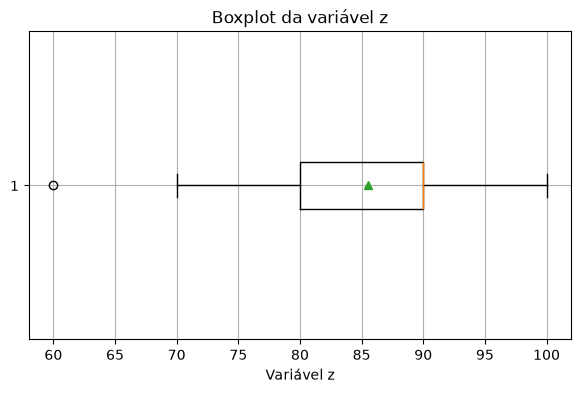

In [33]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    z_ord,
    orientation='horizontal',
    showmeans=True
)

ax.set_title("Boxplot da variável z")
ax.set_xlabel("Variável z")
ax.grid(True)

plt.show()

4 – Após um tratamento, seis operários submeteram-se a um teste e, mais tarde, mediu-se a produtividade de cada um deles. A partir dos resultados apresentados na tabela abaixo, calcule o coeficiente de correlação entre a nota do teste e a produtividade. O que podemos aferir desse resultado? Calcule também a assimetria da amostra teste e da amostra produtividade e compare-as.

| Operário | 1 | 2  | 3  | 4  | 5  | 6  |
|---------:|--:|---:|---:|---:|---:|---:|
| Teste | 9 | 17 | 20 | 19 | 20 | 23 |
| Produtividade | 22 | 34 | 29 | 33 | 42 | 32 |

5– Procurando quantificar os efeitos da escassez de sono sobre a capacidade de resolução de problemas simples, um agente tomou ao acaso 10 sujeitos e os submeteu a experimentação. Deixou-os sem dormir por diferentes números de horas, após o que solicitou que os mesmos resolvessem os itens "contas de adicionar" de um teste. Obteve, assim, os seguintes dados: 

| Nº de erros — Y | Horas sem dormir — X |
|----------------:|----------------------:|
| 8  | 8  |
| 6  | 8  |
| 6  | 12 |
| 10 | 12 |
| 8  | 16 |
| 14 | 16 |
| 14 | 20 |
| 12 | 20 |
| 16 | 24 |
| 12 | 24 |

Calcule o coeficiente de correlação. Pode-se concluir que horas sem dormir afeta a capacidade de um sujeito durante um teste? 

6 – Em um exame de colesterol, o grau médio de um grupo “A” de 150 pessoas foi de 214 mg/dl e um desvio-padrão de 22 mg/dl. Em outro grupo “B”, entretanto, o grau médio em 150 pessoas foi de 201 mg/dl e um desvio-padrão de 21 mg/dl. Em que grupo foi maior a dispersão? 

| Renda familiar (X) | Gasto com alimentação (Y) |
|-------------------:|--------------------------:|
| 3   | 1,5  |
| 5   | 2,0  |
| 10  | 6,0  |
| 10  | 7,0  |
| 20  | 10,0 |
| 20  | 12,0 |
| 20  | 15,0 |
| 30  | 8,0  |
| 40  | 10,0 |
| 50  | 20,0 |
| 60  | 20,0 |
| 70  | 25,0 |
| 70  | 30,0 |
| 80  | 25,0 |
| 100 | 40,0 |
| 100 | 35,0 |
| 100 | 40,0 |
| 120 | 30,0 |
| 120 | 40,0 |
| 140 | 40,0 |
| 150 | 50,0 |
| 180 | 40,0 |
| 180 | 50,0 |
| 200 | 60,0 |
| 200 | 50,0 |


- Calcule a distribuição de frequências das duas variáveis aleatórias.  
- ~~Calcule a distribuição de frequências conjunta das duas variáveis aleatórias.~~  
- Calcule o coeficiente de variação de cada uma das duas variáveis aleatórias e interprete-os. 
- Calcule o coeficiente de correlação entre a renda familiar e o gasto com alimentação desse conjunto de indivíduos. Interprete-o. 
- Calcule os quartis das duas distribuições de frequências. Monte o diagrama de Box-Plot. 

7 - renda familiar e gastos com alimentação.

In [34]:
renda_familiar = [
    3, 5, 10, 10, 20, 20,
    20, 30, 40, 50, 60, 70,
    70, 80, 100, 100, 100,
    120, 120, 140, 150, 180,
    180, 200, 200
]

n_renda = len(renda_familiar)

dados_renda = pd.DataFrame({
    "Renda Familiar": renda_familiar
})

freq_renda = (
    dados_renda["Renda Familiar"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_renda.columns = ["Renda", "fi_renda"]

freq_renda["Fi_renda"] = freq_renda["fi_renda"].cumsum()
freq_renda["fr_renda"] = freq_renda["fi_renda"] / n_renda
freq_renda["Fr_renda"] = freq_renda["fr_renda"].cumsum()

freq_renda


,Renda,fi_renda,Fi_renda,fr_renda,Fr_renda
0,3,1,1,0.04,0.04
1,5,1,2,0.04,0.08
2,10,2,4,0.08,0.16
3,20,3,7,0.12,0.28
4,30,1,8,0.04,0.32
5,40,1,9,0.04,0.36
6,50,1,10,0.04,0.40
7,60,1,11,0.04,0.44
8,70,2,13,0.08,0.52
9,80,1,14,0.04,0.56


### Estatísticas.

a média é:

$$ \bar{x} = \sum(fr_i \cdot x_i) $$

a variância populacional é:

$$
\sigma^2 =
\frac{\sum f_i (x_i - \bar{x})^2}{n}
$$

e o desvio padrão:

$$
\sigma = \sqrt{\sigma^2}
$$

e a assimetria pelo terceiro momento padronizado:

$$
g =
\frac{\sum f_i (x_i - \bar{x})^3}
{n\,\sigma^3}
$$


In [35]:
# média

media_renda = (
    freq_renda["Renda"] * freq_renda["fr_renda"]
).sum()

var_renda = (
    freq_renda["fi_renda"]
    * (freq_renda["Renda"] - media_renda)**2
).sum() / n_renda

std_renda = np.sqrt(var_renda)

cv_renda = std_renda / media_renda * 100

g_renda = (
    freq_renda["fi_renda"]
    * (freq_renda["Renda"] - media_renda)**3
).sum() / (n_renda * std_renda**3)

print(f'O valor da média da renda é: {media_renda:.2f}')
print(f'O valor da variância da renda é: {var_renda:.2f}')
print(f'O valor do desvio padrão da renda é: {std_renda:.2f}')
print(f'O valor do coeficiente de variação é: {cv_renda:.2f}%')
print(f'O valor da assimetria é: {g_renda:.2f}')


O valor da média da renda é: 83.12
O valor da variância da renda é: 3968.43
O valor do desvio padrão da renda é: 63.00
O valor do coeficiente de variação é: 75.79%
O valor da assimetria é: 0.45


*O coeficiente de variação (CV) mede a dispersão dos dados em relação à média. Um CV baixo indica alta homogeneidade e estabilidade, enquanto um CV alto aponta grande dispersão e instabilidade. O valor padrão geral classifica variações até 10% como baixas, e acima de 30% como muito altas.*

## Quantis da renda familiar.

In [36]:
renda_ord = sorted(renda_familiar)

mediana_renda_familiar = renda_ord[12]
q1_renda_familiar = (renda_ord[5] + renda_ord[6]) / 2
q3_renda_familiar = (renda_ord[18] + renda_ord[19]) / 2

print(renda_ord)
print(f'A mediana da renda é: {mediana_renda_familiar:.2f}')
print(f'O valor de Q1 da renda é: {q1_renda_familiar:.2f}')
print(f'O valor de Q3 da renda é: {q3_renda_familiar:.2f}')


[3, 5, 10, 10, 20, 20, 20, 30, 40, 50, 60, 70, 70, 80, 100, 100, 100, 120, 120, 140, 150, 180, 180, 200, 200]
A mediana da renda é: 70.00
O valor de Q1 da renda é: 20.00
O valor de Q3 da renda é: 130.00


Para o gráfico eu vou usar o recurso do Python.

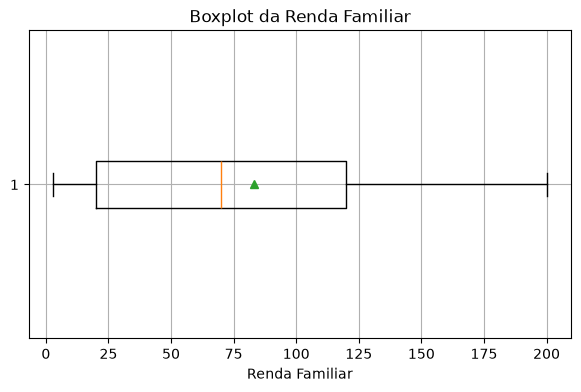

In [37]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    renda_familiar,
    orientation='horizontal',
    showmeans=True
)

ax.set_title("Boxplot da Renda Familiar")
ax.set_xlabel("Renda Familiar")
ax.grid(True)

plt.show()

## Variável Y custos da alimentação

In [38]:
aliment = [
    1.5, 2, 6, 7, 10, 12,
    15, 8, 10, 20, 20, 25,
    30, 25, 40, 35, 40,
    30, 40, 40, 50, 40,
    50, 60, 50
]

n_aliment = len(aliment)

dados_aliment = pd.DataFrame({
    "Gastos com Alimentação": aliment
})

freq_aliment = (
    dados_aliment["Gastos com Alimentação"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_aliment.columns = ["Gastos com Alimentação", "fi_aliment"]

freq_aliment["Fi_aliment"] = freq_aliment["fi_aliment"].cumsum()
freq_aliment["fr_aliment"] = freq_aliment["fi_aliment"] / n_aliment
freq_aliment["Fr_aliment"] = freq_aliment["fr_aliment"].cumsum()

freq_aliment


,Gastos com Alimentação,fi_aliment,Fi_aliment,fr_aliment,Fr_aliment
0,1.5,1,1,0.04,0.04
1,2.0,1,2,0.04,0.08
2,6.0,1,3,0.04,0.12
3,7.0,1,4,0.04,0.16
4,8.0,1,5,0.04,0.20
5,10.0,2,7,0.08,0.28
6,12.0,1,8,0.04,0.32
7,15.0,1,9,0.04,0.36
8,20.0,2,11,0.08,0.44
9,25.0,2,13,0.08,0.52


In [39]:
media_aliment = (
    freq_aliment["Gastos com Alimentação"] * freq_aliment["fr_aliment"]
).sum()

var_aliment = (
    freq_aliment["fi_aliment"]
    * (freq_aliment["Gastos com Alimentação"] - media_aliment)**2
).sum() / n_aliment

std_aliment = np.sqrt(var_aliment)

cv_aliment = std_aliment / media_aliment * 100

g_aliment = (
    freq_aliment["fi_aliment"]
    * (freq_aliment["Gastos com Alimentação"] - media_aliment)**3
).sum() / (n_aliment * std_aliment**3)

print(f'O valor da média dos gastos com alimentação é: {media_aliment:.2f}')
print(f'O valor da variância dos gastos com alimentação é: {var_aliment:.2f}')
print(f'O valor do desvio padrão dos gastos com alimentação é: {std_aliment:.2f}')
print(f'O valor do coeficiente de variação é: {cv_aliment:.2f}%')
print(f'O valor da assimetria é: {g_aliment:.2f}')


O valor da média dos gastos com alimentação é: 26.66
O valor da variância dos gastos com alimentação é: 285.21
O valor do desvio padrão dos gastos com alimentação é: 16.89
O valor do coeficiente de variação é: 63.35%
O valor da assimetria é: 0.16


### Quantis dos gastos com Alimentação.

In [40]:
aliment_ord = sorted(aliment)

mediana_aliment = aliment_ord[12]
q1_aliment = (aliment_ord[5] + aliment_ord[6]) / 2
q3_aliment = (aliment_ord[18] + aliment_ord[19]) / 2

print(aliment_ord)
print(f'A mediana dos gastos com alimentação é: {mediana_aliment:.2f}')
print(f'O valor de Q1 dos gastos com alimentação é: {q1_aliment:.2f}')
print(f'O valor de Q3 dos gastos com alimentação é: {q3_aliment:.2f}')


[1.5, 2, 6, 7, 8, 10, 10, 12, 15, 20, 20, 25, 25, 30, 30, 35, 40, 40, 40, 40, 40, 50, 50, 50, 60]
A mediana dos gastos com alimentação é: 25.00
O valor de Q1 dos gastos com alimentação é: 10.00
O valor de Q3 dos gastos com alimentação é: 40.00


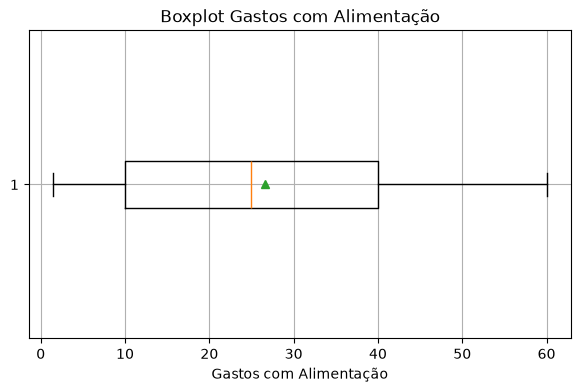

In [41]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    aliment,
    orientation='horizontal',
    showmeans=True
)

ax.set_title("Boxplot Gastos com Alimentação")
ax.set_xlabel("Gastos com Alimentação")
ax.grid(True)

plt.show()


8- Os valores da precipitação (em mm) registrada em uma Estação Meteorológica, nos 31 dias de janeiro de 2014, estão listados na tabela:

| Dia | Precipitação |
|----:|-------------:|
| 1  | 0.0  |
| 2  | 0.0  |
| 3  | 0.0  |
| 4  | 0.0  |
| 5  | 4.7  |
| 6  | 0.6  |
| 7  | 17.2 |
| 8  | 1.4  |
| 9  | 11.2 |
| 10 | 1.0  |
| 11 | 3.8  |
| 12 | 0.3  |
| 13 | 0.0  |
| 14 | 0.0  |
| 15 | 0.5  |
| 16 | 7.0  |
| 17 | 0.0  |
| 18 | 0.0  |
| 19 | 3.3  |
| 20 | 7.6  |
| 21 | 0.9  |
| 22 | 0.3  |
| 23 | 18.2 |
| 24 | 4.0  |
| 25 | 4.6  |
| 26 | 22.0 |
| 27 | 15.6 |
| 28 | 0.0  |
| 29 | 3.4  |
| 30 | 0.0  |
| 31 | 0.0  |

- Escolha a melhor forma de representar os dados: representação individual ou por classes. Justifique. 
- Apresente a distribuição de frequências relativa e a distribuição de frequências relativa acumulada. 
- Apresente estatísticas de valores centrais. 
- Apresente estatísticas de dispersão. 
- Apresente estatísticas de forma. - Apresente o boxplot (gráfico de caixa) da variável aleatória. 
- Calcule os valores da variável aleatória correspondentes ao 1º, 2º e 3º quartis. 

In [42]:
dia = list(range(1, 32))

precipita = [0.0, 0.0, 0.0, 0.0, 4.7, 0.6, 17.2, 1.4, 11.2,
             1.0, 3.8, 0.3, 0.0, 0.0, 0.5, 7, 0.0, 0.0, 3.3, 7.6, 0.9,
             0.3, 18.2, 4, 4.6, 22, 15.6, 0, 3.4, 0.0, 0.0]
n_precipita = len(precipita)

dados_precipita = pd.DataFrame({
    "Dia": dia, "Precipitação": precipita
})


freq_precipita = (
    dados_precipita["Precipitação"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_precipita.columns = ["Precipitação", "fi_precipita"]

freq_precipita["Fi_precipita"] = freq_precipita["fi_precipita"].cumsum()
freq_precipita["fr_precipita"] = freq_precipita["fi_precipita"] / n_precipita
freq_precipita["Fr_precipita"] = freq_precipita["fr_precipita"].cumsum()

freq_precipita


,Precipitação,fi_precipita,Fi_precipita,fr_precipita,Fr_precipita
0,0.0,11,11,0.354839,0.354839
1,0.3,2,13,0.064516,0.419355
2,0.5,1,14,0.032258,0.451613
3,0.6,1,15,0.032258,0.483871
4,0.9,1,16,0.032258,0.516129
5,1.0,1,17,0.032258,0.548387
6,1.4,1,18,0.032258,0.580645
7,3.3,1,19,0.032258,0.612903
8,3.4,1,20,0.032258,0.645161
9,3.8,1,21,0.032258,0.677419


In [43]:
# Média
media_precipita = (
    freq_precipita["fr_precipita"]
    * freq_precipita["Precipitação"]
).sum()

# Variância populacional pela tabela de frequências
var_precipita = (
    freq_precipita["fi_precipita"]
    * (freq_precipita["Precipitação"] - media_precipita)**2
).sum() / n_precipita

# desvio padrão

std_precipita = np.sqrt(var_precipita)

moda_precipita = freq_precipita.loc[
    freq_precipita["fi_precipita"].idxmax(),
    "Precipitação"
]

precipita_ord = sorted(precipita)
mediana_precipita = precipita_ord[15]

print(f'A média da precipitação é: {media_precipita:.2f}')
print(f'A variância da precipitação é: {var_precipita:.2f}')
print(f'O desvio padrão da precipitação é: {std_precipita:.2f}')
print(f'A moda da precipitação é: {moda_precipita:.2f}')
print(f'A mediana da precipitação é: {mediana_precipita:.2f}')


A média da precipitação é: 4.12
A variância da precipitação é: 37.49
O desvio padrão da precipitação é: 6.12
A moda da precipitação é: 0.00
A mediana da precipitação é: 0.90


## Parte 2

# Covariância e correlação linear

## 1. Relação entre duas variáveis quantitativas

Até aqui, estudamos medidas que descrevem uma variável isoladamente, como média, variância e desvio padrão. Entretanto, muitas análises estatísticas procuram verificar se existe alguma relação entre **duas variáveis quantitativas** observadas nos mesmos indivíduos ou elementos da amostra.

Alguns exemplos são:

- altura e massa corporal de uma pessoa;
- temperatura e salinidade da água do mar;
- velocidade do vento e altura das ondas;
- tempo de estudo e nota obtida em uma prova.

Cada observação é representada por um par ordenado:

$$
(x_i,y_i),
$$

em que $x_i$ é o valor da variável $X$ e $y_i$ é o valor correspondente da variável $Y$ na mesma observação.

Antes de calcular qualquer medida numérica, é recomendável representar os pares de valores em um **diagrama de dispersão**.

## 2. Diagrama de dispersão

No diagrama de dispersão (*scatter plot*), os valores da variável $X$ são colocados no eixo horizontal, enquanto os valores da variável $Y$ são colocados no eixo vertical. Cada par $(x_i,y_i)$ aparece como um ponto no gráfico.

O gráfico permite observar três características importantes da relação entre as variáveis:

1. **Direção**: positiva, negativa ou sem direção evidente;
2. **Forma**: linear ou não linear;
3. **Intensidade**: pontos mais próximos ou mais afastados de uma tendência.

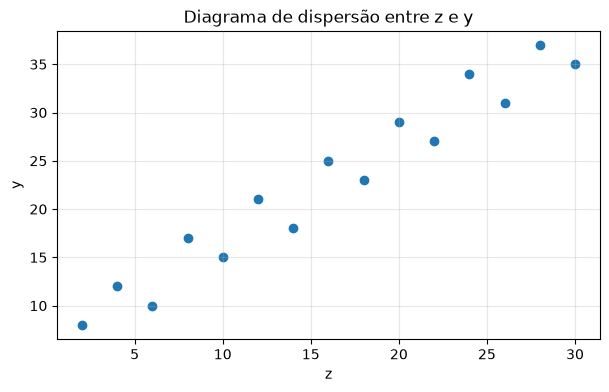

In [44]:
fig, ax = plt.subplots(figsize=(7, 4))

z = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]

y = [8, 12, 10, 17, 15, 21, 18, 25, 23, 29, 27, 34, 31, 37, 35]

plt.scatter(z, y)

plt.xlabel("z")
plt.ylabel("y")
plt.title("Diagrama de dispersão entre z e y")
plt.grid(alpha=0.3)

plt.show()

### Relação positiva

Quando os valores de $X$ aumentam e os valores de $Y$ também tendem a aumentar, a relação apresenta direção positiva. No gráfico, os pontos mostram uma tendência ascendente da esquerda para a direita. O gráfico acima demonstra uma **tendência linear positiva forte**.

### Relação negativa

Quando os valores de $X$ aumentam e os valores de $Y$ tendem a diminuir, a relação apresenta direção negativa. Nesse caso, os pontos mostram uma tendência descendente da esquerda para a direita.

### Ausência de relação linear evidente

Quando os pontos ficam muito dispersos e não apresentam uma tendência crescente ou decrescente, pode não haver uma relação linear evidente. Isso não significa necessariamente que as variáveis sejam completamente independentes, pois pode existir uma relação não linear.

## 3. Covariância

A covariância é uma medida numérica que indica como duas variáveis variam conjuntamente em relação às suas médias.

Para compreender a ideia, observamos os produtos:

$$
(x_i-\bar{x})(y_i-\bar{y}).
$$

Esses produtos podem ser interpretados da seguinte forma:

- se $x_i$ e $y_i$ estiverem ambos acima de suas médias, o produto será positivo;
- se $x_i$ e $y_i$ estiverem ambos abaixo de suas médias, o produto também será positivo;
- se um valor estiver acima de sua média e o outro abaixo, o produto será negativo.

Portanto, quando as duas variáveis tendem a aumentar ou diminuir juntas, predominam produtos positivos. Quando uma tende a aumentar enquanto a outra diminui, predominam produtos negativos.

### Covariância amostral

Para uma amostra com $n$ pares de observações, a covariância amostral é calculada por:

$$
s_{XY}=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{n-1}.
$$

Nessa expressão:

- $x_i$ e $y_i$ são os valores de cada par de observações;
- $\bar{x}$ é a média da variável $X$;
- $\bar{y}$ é a média da variável $Y$;
- $n$ é o número de pares de observações;
- $s_{XY}$ é a covariância amostral entre $X$ e $Y$.

### Interpretação do sinal da covariância

- $s_{XY}>0$: as variáveis apresentam tendência conjunta positiva;
- $s_{XY}<0$: as variáveis apresentam tendência conjunta negativa;
- $s_{XY}\approx 0$: não há tendência **linear** conjunta evidente.

O valor da covariância depende das unidades e das escalas das duas variáveis. Se $X$ for medido em metros e $Y$ em segundos, por exemplo, a unidade da covariância será metro-segundo. Além disso, uma simples mudança de escala pode alterar bastante seu valor numérico.

Por essa razão, a covariância é útil principalmente para indicar a **direção** da relação, mas seu módulo não possui uma escala padronizada que permita avaliar facilmente a intensidade da associação.

Então é interessante trazer o problema 3 da primeira parte e calcular a variância

3– Sejam os dados de tempos de reação a um estímulo (Y) e acuidade visual (Z) de 20 indivíduos.  

| Indivíduo |  Y  |  Z  |
|----------:|----:|----:|
| 1  | 96  | 90  |
| 2  | 92  | 100 |
| 3  | 106 | 80  |
| 4  | 100 | 90  |
| 5  | 98  | 100 |
| 6  | 104 | 90  |
| 7  | 110 | 80  |
| 8  | 101 | 90  |
| 9  | 116 | 70  |
| 10 | 106 | 100 |
| 11 | 109 | 90  |
| 12 | 100 | 80  |
| 13 | 112 | 90  |
| 14 | 105 | 80  |
| 15 | 118 | 70  |
| 16 | 108 | 90  |
| 17 | 113 | 90  |
| 18 | 112 | 90  |
| 19 | 127 | 60  |
| 20 | 117 | 80  |



Média de Y: 107.50
Média de Z: 85.50
Soma dos produtos: -1235.00
Covariância amostral: -65.00


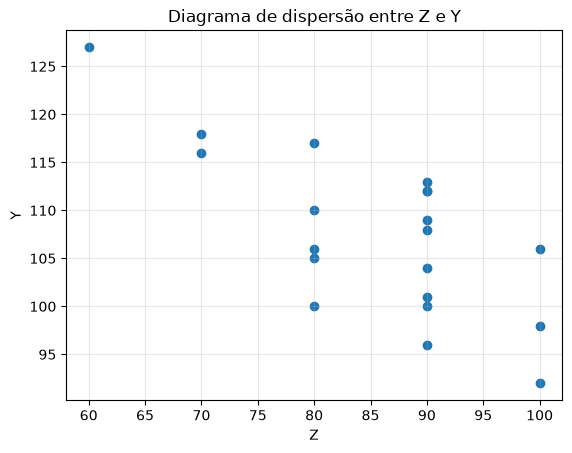

,indivíduo,y,z,Y - média de Y,Z - média de Z,produto
0,1,96,90,-11.5,4.5,-51.75
1,2,92,100,-15.5,14.5,-224.75
2,3,106,80,-1.5,-5.5,8.25
3,4,100,90,-7.5,4.5,-33.75
4,5,98,100,-9.5,14.5,-137.75
5,6,104,90,-3.5,4.5,-15.75
6,7,110,80,2.5,-5.5,-13.75
7,8,101,90,-6.5,4.5,-29.25
8,9,116,70,8.5,-15.5,-131.75
9,10,106,100,-1.5,14.5,-21.75


In [45]:
y = [96, 92, 106, 100, 98, 104, 110, 101, 116, 106,
     109, 100, 112, 105, 118, 108, 113, 112, 127, 117]

z = [90, 100, 80, 90, 100, 90, 80, 90, 70, 100,
     90, 80, 90, 80, 70, 90, 90, 90, 60, 80]

n = len(y)

med_y = np.mean(y)
med_z = np.mean(z)

df["Y - média de Y"] = df["y"] - med_y
df["Z - média de Z"] = df["z"] - med_z

df["produto"] = (
    df["Y - média de Y"]
    * df["Z - média de Z"]
)

soma_produtos = df["produto"].sum()
cov_yz = soma_produtos / (n - 1)

print(f"Média de Y: {med_y:.2f}")
print(f"Média de Z: {med_z:.2f}")
print(f"Soma dos produtos: {soma_produtos:.2f}")
print(f"Covariância amostral: {cov_yz:.2f}")

plt.scatter(z, y)

plt.xlabel("Z")
plt.ylabel("Y")
plt.title("Diagrama de dispersão entre Z e Y")
plt.grid(alpha=0.3)

plt.show()

df

## 4. Coeficiente de correlação linear de Pearson

O coeficiente de correlação linear de Pearson transforma a covariância em uma medida adimensional e padronizada. Para isso, divide-se a covariância pelo produto dos desvios padrão das duas variáveis:

$$
r=\frac{s_{XY}}{s_Xs_Y}.
$$

Substituindo as expressões da covariância e dos desvios padrão, também podemos escrever:

$$
r=
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\,
 \sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}.
$$

O coeficiente de correlação sempre se encontra no intervalo:

$$
-1\leq r\leq 1.
$$

Como $s_X$ e $s_Y$ são sempre positivos, o sinal de $r$ é o mesmo sinal da covariância.



In [46]:
# Calcular os desvios-padrão.

dp_y = np.std(y, ddof=1)
dp_z = np.std(z, ddof=1)

r = cov_yz / (dp_y * dp_z)

print(f"Desvio padrão de Y: {dp_y:.4f}")
print(f"Desvio padrão de Z: {dp_z:.4f}")
print(f"Coeficiente de Pearson: {r:.4f}")

Desvio padrão de Y: 8.5008
Desvio padrão de Z: 10.5006
Coeficiente de Pearson: -0.7282


## 5. Interpretação do coeficiente de correlação

O sinal do coeficiente indica a **direção** da relação linear:

- $r>0$: correlação linear positiva;
- $r<0$: correlação linear negativa;
- $r\approx 0$: correlação linear ausente ou muito fraca.

O módulo $|r|$ indica o grau de aproximação dos pontos a uma linha reta:

- quanto mais próximo de $1$, mais forte é a associação linear;
- quanto mais próximo de $0$, mais fraca é a associação linear.

Os casos extremos são:

- $r=1$: correlação linear positiva perfeita;
- $r=-1$: correlação linear negativa perfeita;
- $r=0$: ausência de correlação **linear**.

Como orientação inicial, e não como regra universal, pode-se utilizar a seguinte classificação para o módulo de $r$:

| Módulo de $r$ | Interpretação aproximada |
|---:|:---|
| $0{,}00 \leq \lvert r\rvert < 0{,}20$ | muito fraca |
| $0{,}20 \leq \lvert r\rvert < 0{,}40$ | fraca |
| $0{,}40 \leq \lvert r\rvert < 0{,}60$ | moderada |
| $0{,}60 \leq \lvert r\rvert < 0{,}80$ | forte |
| $0{,}80 \leq \lvert r\rvert \leq 1{,}00$ | muito forte |

Esses limites são apenas referências. A interpretação adequada depende da área de estudo, da qualidade das medições, do tamanho da amostra e do fenômeno analisado. Por isso, é recomendável apresentar o valor calculado de $r$ e examinar também o diagrama de dispersão, em vez de informar somente uma classificação verbal.

Por exemplo:

- $r=0{,}87$ indica uma correlação linear positiva muito forte;
- $r=-0{,}72$ indica uma correlação linear negativa forte;
- $r=0{,}08$ indica uma correlação linear positiva muito fraca, praticamente sem tendência linear.

In [47]:
# Classificação do Coeficiente de Pearson,


# Classificação do coeficiente de correlação de Pearson

def analise(r):

    modulo_r = abs(r)

    if 0.0 <= modulo_r < 0.2:
        classificacao = "Muito fraca"
    elif 0.2 <= modulo_r < 0.4:
        classificacao = "Fraca"
    elif 0.4 <= modulo_r < 0.6:
        classificacao = "Moderada"
    elif 0.6 <= modulo_r < 0.8:
        classificacao = "Forte"
    elif 0.8 <= modulo_r <= 1.0:
        classificacao = "Muito forte"
    else:
        classificacao = "Valor inválido"

    return classificacao

analise(r)

'Forte'

## 6. Cuidados na interpretação

### Correlação não implica causalidade

Uma correlação elevada entre duas variáveis não demonstra, por si só, que uma delas cause alterações na outra.  A associação pode resultar da ação de uma terceira variável, de uma coincidência ou de uma relação indireta entre os fenômenos.

### O coeficiente de Pearson mede relações lineares

É possível obter um valor de $r$ próximo de zero mesmo quando existe uma relação não linear forte entre as variáveis. O diagrama de dispersão é essencial para perceber esse tipo de comportamento.

### Valores extremos podem alterar o resultado

O coeficiente de correlação é sensível a valores discrepantes. Um único ponto muito afastado dos demais pode aumentar, diminuir ou até inverter a correlação observada. Por isso, os valores extremos devem ser investigados, mas não eliminados automaticamente.

### A correlação deve ser analisada no contexto

O valor de $r$ resume apenas a direção e a intensidade da associação linear. Uma análise completa deve considerar o gráfico, a natureza das variáveis, o tamanho da amostra, possíveis erros de medição e o conhecimento sobre o fenômeno estudado.

## Síntese

A sequência lógica da análise é:

1. representar os pares de observações em um diagrama de dispersão;
2. observar a direção, a forma e a intensidade aparente da relação;
3. calcular a covariância para identificar a direção da variação conjunta;
4. calcular o coeficiente de correlação para obter uma medida padronizada da associação linear;
5. interpretar o valor de $r$ em conjunto com o gráfico e com o contexto dos dados.

Assim, a covariância fornece a base matemática da correlação, enquanto o coeficiente de correlação facilita a comparação e a interpretação da relação linear entre duas variáveis.


### Exercício.

Dados os valores de vendas avaliar a correlação com os lucros.

In [48]:
df=pd.DataFrame({'Vendas':[201, 225, 305, 380, 560, 600, 685, 735],
                 'Lucro':[17, 20, 21, 23, 25, 24, 27, 27],
                })
df['XY'] = df['Vendas'] * df['Lucro']
df['V2'] = df['Vendas']**2
n = len(df)
print(df)
print()
med_vendas = np.mean(df['Vendas'])
med_lucro = np.mean(df['Lucro'])
soma_xy = np.sum(df['XY'])
soma_x2 = np.sum(df['V2'])
print(f'1 - A média das Vendas é: {med_vendas}')
print(f'2 - A média dos lucros é: {med_lucro}')
print(f'3 - O somatório de xy é: {soma_xy}')
print(f'4 - O somatório de x2 é: {soma_x2}')
print(f'5 - O total de elementos é: {n}')




   Vendas  Lucro     XY      V2
0     201     17   3417   40401
1     225     20   4500   50625
2     305     21   6405   93025
3     380     23   8740  144400
4     560     25  14000  313600
5     600     24  14400  360000
6     685     27  18495  469225
7     735     27  19845  540225

1 - A média das Vendas é: 461.375
2 - A média dos lucros é: 23.0
3 - O somatório de xy é: 89802
4 - O somatório de x2 é: 2011501
5 - O total de elementos é: 8


### Método dos Mínimos Quadrados (MMQ).

A equação da reta da regressão é dada por:

$$
\hat{y} = \alpha + \beta x
$$

onde $\beta$

$$
\beta =
\frac{
\sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}
}{
\sum_{i=1}^{n} x_i^2 - n\bar{x}^{\,2}
}
$$



$$
\beta =
\frac{
89802 - (8\cdot 461,375 \cdot 23)
}{
2011501- (8 \cdot 461,375^2) 
}
$$
$$
\beta = \frac{4909}{308565,875}= 1,591\times 10^{-2}
$$

a partir do valor de $\beta$ calculamos o $\alpha$

$$
\bar{y} = \alpha + \beta\,\bar{x}\; \therefore\; \alpha = \bar{y} - \beta\,\bar{x}
$$

$$
\alpha = \bar{y} - \beta\,\bar{x} = 23 - 1,591\times 10^{-2}\cdot 461{,}375 = 15,66
$$

Então a reta é dada por:

$$
\hat{y} = 15{,}66 +  1,591\times 10^{-2}\,\cdot x
$$

#### Coeficiente de Determinação.

$$
R^2
=
1-
\frac{
\displaystyle\sum_{i=1}^{n}(y_i-\widehat{y}_i)^2
}{
\displaystyle\sum_{i=1}^{n}(y_i-\bar{y})^2
}
$$

A média das vendas é: 461.38
O somatório dos produtos xiyi é: 89802.00
O somatório das vendas ao quadrado é: 2011501.00
O valor de β é: 1.59e-02
O valor de α é: 15.66


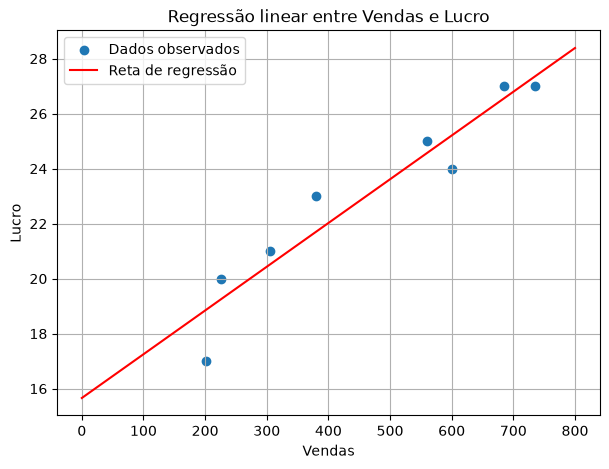

In [71]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

n = len(df)

med_x = sum(df['Vendas']) / n
med_y = sum(df['Lucro']) / n

print(f'A média das vendas é: {med_x:.2f}')

soma_XY = sum(df['XY'])
print(f'O somatório dos produtos xiyi é: {soma_XY:.2f}')

soma_v2 = sum(df['V2'])
print(f'O somatório das vendas ao quadrado é: {soma_v2:.2f}')

beta = (
    soma_XY - n * med_x * med_y
) / (
    soma_v2 - n * med_x**2
)

print(f'O valor de \u03B2 é: {beta:.2e}')

alpha = med_y - beta * med_x

print(f'O valor de \u03B1 é: {alpha:.2f}')

# Pontos utilizados para desenhar a reta
x_reta = np.linspace(0, 800, 100)
y_reta = alpha + beta * x_reta

# Dados observados
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    df['Vendas'],
    df['Lucro'],
    label='Dados observados'
)

# Reta de regressão
ax.plot(
    x_reta,
    y_reta,
    color='red',
    label='Reta de regressão'
)

ax.set_xlabel('Vendas')
ax.set_ylabel('Lucro')
ax.set_title('Regressão linear entre Vendas e Lucro')
ax.grid(True)
ax.legend()

plt.show()

In [51]:
# Valores estimados pela reta
df['Lucro_estimado'] = alpha + beta * df['Vendas']

# Resíduos: observado - estimado
df['Residuo'] = df['Lucro'] - df['Lucro_estimado']

# Soma dos quadrados dos resíduos
SQ_res = sum(df['Residuo']**2)

# Soma total dos quadrados
SQ_tot = sum((df['Lucro'] - med_y)**2)

# Coeficiente de determinação
R2 = 1 - SQ_res / SQ_tot

print(f'O coeficiente de determinação é R² = {R2:.4f}')
print(f'A regressão explica {R2 * 100:.2f}% da variação do lucro.')

O coeficiente de determinação é R² = 0.9081
A regressão explica 90.81% da variação do lucro.


In [73]:
r = df['Vendas'].corr(df['Lucro'])
R2 = r**2

print(f'r = {r:.4f}')
print(f'R² = {R2:.2%}')

r = 0.9529
R² = 90.81%
